In [15]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/SpamAssasin.csv
/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/Nazario.csv
/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/Nigerian_Fraud.csv
/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/CEAS_08.csv
/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/Enron.csv
/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/Ling.csv
/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/phishing_email.csv


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from imblearn.over_sampling import SMOTE

In [34]:
spam = pd.read_csv('/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/SpamAssasin.csv')
ceas = pd.read_csv('/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/CEAS_08.csv')
ling = pd.read_csv('/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/Ling.csv')
enron = pd.read_csv('/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/Enron.csv')
nazario= pd.read_csv('/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/Nazario.csv')
nigerian= pd.read_csv('/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/Nigerian_Fraud.csv')
phishing = pd.read_csv('/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/phishing_email.csv')


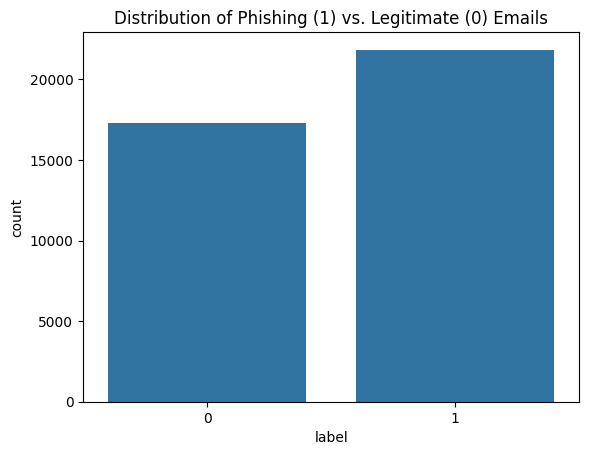

Shape: (39154, 7)
Columns: ['sender', 'receiver', 'date', 'subject', 'body', 'label', 'urls']

Label distribution:
label
1    21842
0    17312
Name: count, dtype: int64

Missing values:
sender        0
receiver    462
date          0
subject      28
body          0
label         0
urls          0
dtype: int64

Duplicates: 0


In [31]:
sns.countplot(x='label', data=ceas)
plt.title('Distribution of Phishing (1) vs. Legitimate (0) Emails')
plt.show()

print(f'Shape: {ceas.shape}')
print(f'Columns: {list(ceas.columns)}')
print('\nLabel distribution:')
print(ceas['label'].value_counts())
print('\nMissing values:')
print(ceas.isnull().sum())
print(f'\nDuplicates: {ceas.duplicated().sum()}')

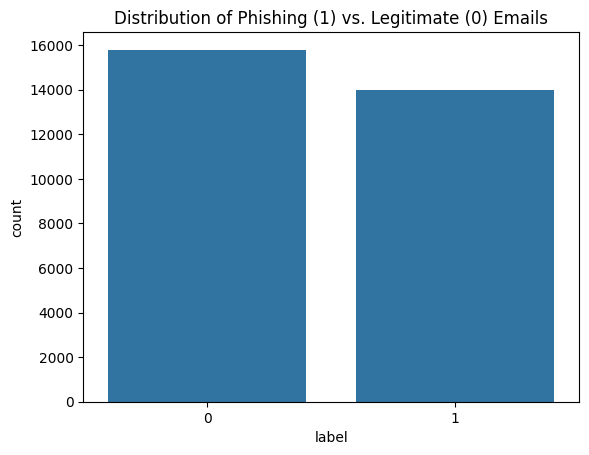

Shape: (29767, 3)
Columns: ['subject', 'body', 'label']

Label distribution:
label
0    15791
1    13976
Name: count, dtype: int64

Missing values:
subject    198
body         0
label        0
dtype: int64

Duplicates: 0


In [32]:
sns.countplot(x='label', data=enron)
plt.title('Distribution of Phishing (1) vs. Legitimate (0) Emails')
plt.show()

print(f'Shape: {enron.shape}')
print(f'Columns: {list(enron.columns)}')
print('\nLabel distribution:')
print(enron['label'].value_counts())
print('\nMissing values:')
print(enron.isnull().sum())
print(f'\nDuplicates: {enron.duplicated().sum()}')

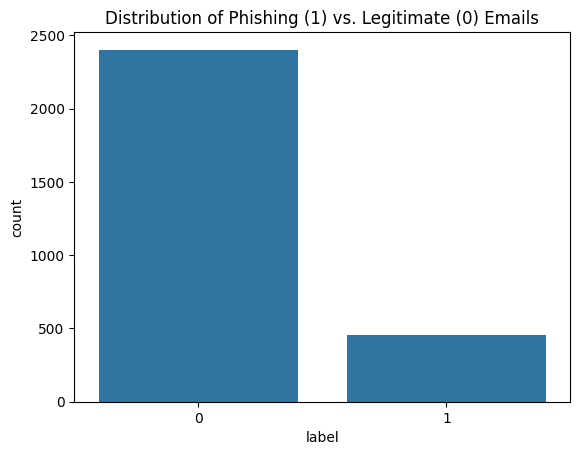

Shape: (2859, 3)
Columns: ['subject', 'body', 'label']

Label distribution:
label
0    2401
1     458
Name: count, dtype: int64

Missing values:
subject    62
body        0
label       0
dtype: int64

Duplicates: 0


In [35]:
sns.countplot(x='label', data=ling)
plt.title('Distribution of Phishing (1) vs. Legitimate (0) Emails')
plt.show()

print(f'Shape: {ling.shape}')
print(f'Columns: {list(ling.columns)}')
print('\nLabel distribution:')
print(ling['label'].value_counts())
print('\nMissing values:')
print(ling.isnull().sum())
print(f'\nDuplicates: {ling.duplicated().sum()}')

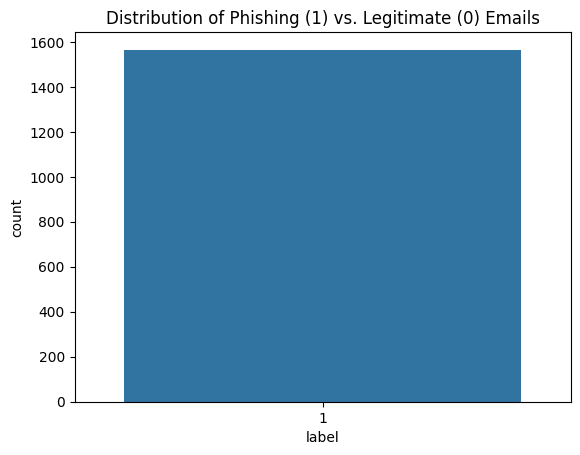

Shape: (1565, 7)
Columns: ['sender', 'receiver', 'date', 'subject', 'body', 'urls', 'label']

Label distribution:
label
1    1565
Name: count, dtype: int64

Missing values:
sender       0
receiver    96
date         1
subject      4
body         0
urls         0
label        0
dtype: int64

Duplicates: 0


In [36]:
sns.countplot(x='label', data=nazario)
plt.title('Distribution of Phishing (1) vs. Legitimate (0) Emails')
plt.show()

print(f'Shape: {nazario.shape}')
print(f'Columns: {list(nazario.columns)}')
print('\nLabel distribution:')
print(nazario['label'].value_counts())
print('\nMissing values:')
print(nazario.isnull().sum())
print(f'\nDuplicates: {nazario.duplicated().sum()}')

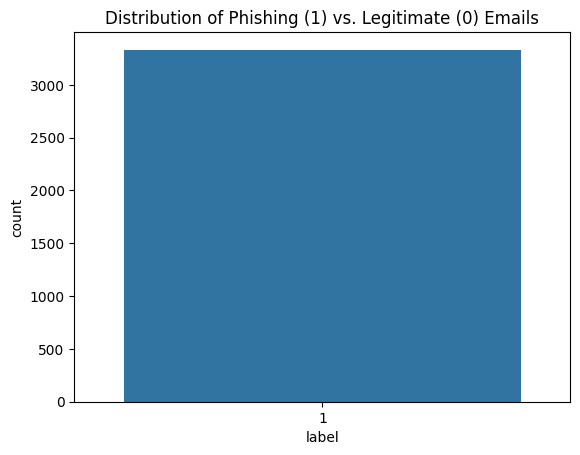

Shape: (3332, 7)
Columns: ['sender', 'receiver', 'date', 'subject', 'body', 'urls', 'label']

Label distribution:
label
1    3332
Name: count, dtype: int64

Missing values:
sender       331
receiver    1324
date         482
subject       39
body           0
urls           0
label          0
dtype: int64

Duplicates: 0


In [37]:
sns.countplot(x='label', data=nigerian)
plt.title('Distribution of Phishing (1) vs. Legitimate (0) Emails')
plt.show()

print(f'Shape: {nigerian.shape}')
print(f'Columns: {list(nigerian.columns)}')
print('\nLabel distribution:')
print(nigerian['label'].value_counts())
print('\nMissing values:')
print(nigerian.isnull().sum())
print(f'\nDuplicates: {nigerian.duplicated().sum()}')

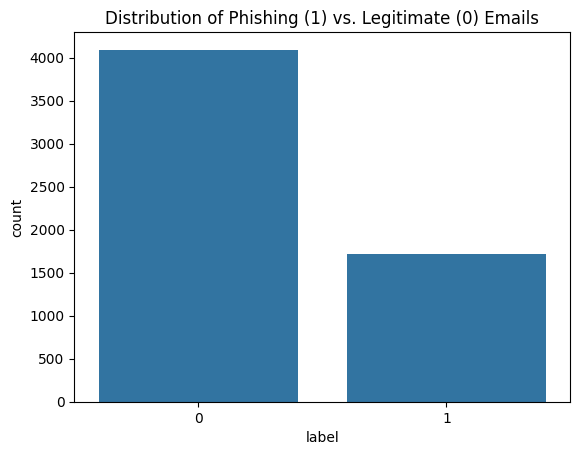

Shape: (5809, 7)
Columns: ['sender', 'receiver', 'date', 'subject', 'body', 'label', 'urls']

Label distribution:
label
0    4091
1    1718
Name: count, dtype: int64

Missing values:
sender        0
receiver    210
date          0
subject      16
body          1
label         0
urls          0
dtype: int64

Duplicates: 0


In [38]:
sns.countplot(x='label', data=spam)
plt.title('Distribution of Phishing (1) vs. Legitimate (0) Emails')
plt.show()

print(f'Shape: {spam.shape}')
print(f'Columns: {list(spam.columns)}')
print('\nLabel distribution:')
print(spam['label'].value_counts())
print('\nMissing values:')
print(spam.isnull().sum())
print(f'\nDuplicates: {spam.duplicated().sum()}')

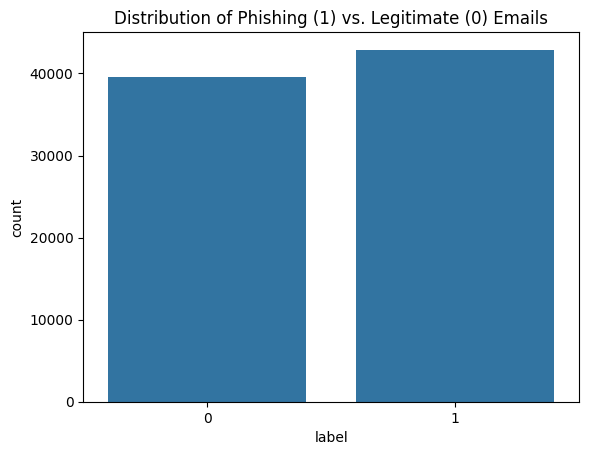

Shape: (82486, 2)
Columns: ['text_combined', 'label']

Label distribution:
label
1    42891
0    39595
Name: count, dtype: int64

Missing values:
text_combined    0
label            0
dtype: int64

Duplicates: 408


In [39]:
sns.countplot(x='label', data=phishing)
plt.title('Distribution of Phishing (1) vs. Legitimate (0) Emails')
plt.show()

print(f'Shape: {phishing.shape}')
print(f'Columns: {list(phishing.columns)}')
print('\nLabel distribution:')
print(phishing['label'].value_counts())
print('\nMissing values:')
print(phishing.isnull().sum())
print(f'\nDuplicates: {phishing.duplicated().sum()}')